In [2]:
import pandas as pd

def clean_data(df):
    # Sort by column: 'gap_score' (descending)
    df = df.sort_values(['gap_score'], ascending=[False])
    return df

# Loaded variable 'df' from URI: c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\dupage_township_pop_ranked.csv
df = pd.read_csv(r'c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\dupage_township_pop_ranked.csv')

df_clean = clean_data(df.copy())
df_clean.head()

,TownshipName,muslim_foreign_born,naturalized_citizens,non_citizens,township,registered,ballots_cast,turnout,concentration_norm,turnout_norm,gap_score
1,Bloomingdale,2878,18450,10187,Bloomingdale,69894,32750,46.856669,1.000000,0.000000,1.000000
0,Addison,707,13916,9977,Addison,50373,23874,47.394437,0.137465,0.035467,0.101998
2,Downers Grove,2809,15907,9828,Downers Grove,106273,64204,60.414216,0.972586,0.894155,0.078431
6,Wayne,1260,9858,3837,Wayne,43982,22681,51.568824,0.357171,0.310779,0.046392
5,Naperville,1222,11705,12879,Naperville,65008,34073,52.413549,0.342074,0.366491,-0.024417


In [3]:
import pandas as pd

def clean_data(df):
    # Sort by column: 'gap_score' (descending)
    df = df.sort_values(['gap_score'], ascending=[False])
    return df

# Loaded variable 'df' from URI: c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\township_ranked.csv
df = pd.read_csv(r'c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\township_ranked.csv')

df_clean = clean_data(df.copy())
df_clean.head()

,Township_Name,muslim_foreign_born,naturalized_citizens,non_citizens,registered,voters_cast,turnout,concentration_norm,turnout_norm,gap_score,tier
0,NILES,9307,31106,10098,73857,31967,43.282289,1.000000,0.522290,0.477710,High
1,CICERO,259,14136,20522,32174,8165,25.377634,0.027097,0.000000,0.027097,High
2,MAINE,5439,31221,15559,85011,38263,45.009469,0.584086,0.572672,0.011414,High
3,HANOVER,2013,17477,16996,55807,20215,36.223054,0.215699,0.316367,-0.100669,Medium
4,STICKNEY,531,6240,5302,23069,7624,33.048680,0.056344,0.223769,-0.167425,Medium


In [4]:
import pandas as pd

def clean_data(df):
    # Sort by column: 'gap_score' (ascending)
    df = df.sort_values(['gap_score'])
    # Sort by column: 'gap_score' (descending)
    df = df.sort_values(['gap_score'], ascending=[False])
    return df

# Loaded variable 'df' from URI: c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\ward_ranked.csv
df = pd.read_csv(r'c:\Users\abdif\Downloads\CAIR Intern Data\Civic_Engagement_Gap_Analysis\ward_ranked.csv')

df_clean = clean_data(df.copy())
df_clean.head()

,Ward,muslim_foreign_born,naturalized_citizens,non_citizens,registered,total,turnout,concentration_norm,turnout_norm,gap_score,tier
0,50.0,3888,11849,10557,28116,11970,42.573624,1.000000,0.385679,0.614321,High
1,14.0,138,9346,12251,20006,5463,27.306808,0.035494,0.018821,0.016673,High
2,12.0,345,9023,11993,20824,6204,29.792547,0.088735,0.078553,0.010182,High
3,15.0,0,3376,6119,20544,5449,26.523559,0.000000,0.000000,0.000000,Below Threshold
4,22.0,0,8139,12169,19534,5465,27.976861,0.000000,0.034922,-0.034922,Below Threshold


In [ ]:
import pandas as pd

ward = pd.read_csv(r'ward_ranked.csv')
township = pd.read_csv(r'township_ranked.csv')
dupage = pd.read_csv(r'dupage_township_pop_ranked.csv')

ward = ward.rename(columns={'Ward': 'area'})
ward['area'] = 'Ward ' + ward['area'].astype(int).astype(str)
ward['county'] = 'Chicago Ward'

township = township.rename(columns={'Township_Name': 'area'})
township['county'] = 'Cook Township'

dupage = dupage.rename(columns={'TownshipName': 'area'})
dupage['county'] = 'DuPage Township'

combined = pd.concat([
    ward[['area', 'gap_score', 'county']],
    township[['area', 'gap_score', 'county']],
    dupage[['area', 'gap_score', 'county']]
], ignore_index=True)

top10 = combined.sort_values('gap_score', ascending=False).head(10)
top10



,area,gap_score,county
81,Bloomingdale,1.000000,DuPage Township
0,Ward 50,0.614321,Chicago Ward
50,NILES,0.477710,Cook Township
80,Addison,0.101998,DuPage Township
82,Downers Grove,0.078431,DuPage Township
86,Wayne,0.046392,DuPage Township
51,CICERO,0.027097,Cook Township
1,Ward 14,0.016673,Chicago Ward
52,MAINE,0.011414,Cook Township
2,Ward 12,0.010182,Chicago Ward


In [11]:
names = top10.rename(columns={'Bloomingdale': 'Bloomingdale Township', 'Ward 50': 'Chicago 50th Ward', 'NILES': 'Niles Township', 'Addison': 'Addison Township', 'Wayne': 'Wayne Township', 'Downers Grove': 'Downers Grove Township', 'CICERO': 'Cicero Township', 'MAINE': 'Maine Township', 'Ward 14': 'Chicago 14th Ward', 'Ward 12': 'Chicago 12th Ward'})

In [15]:
top10['area'] = top10['area'].replace({'Bloomingdale': 'Bloomingdale Township', 'Ward 50': 'Chicago 50th Ward', 'NILES': 'Niles Township', 'Addison': 'Addison Township', 'Wayne': 'Wayne Township', 'Downers Grove': 'Downers Grove Township',  'CICERO': 'Cicero Township', 'MAINE': 'Maine Township'})

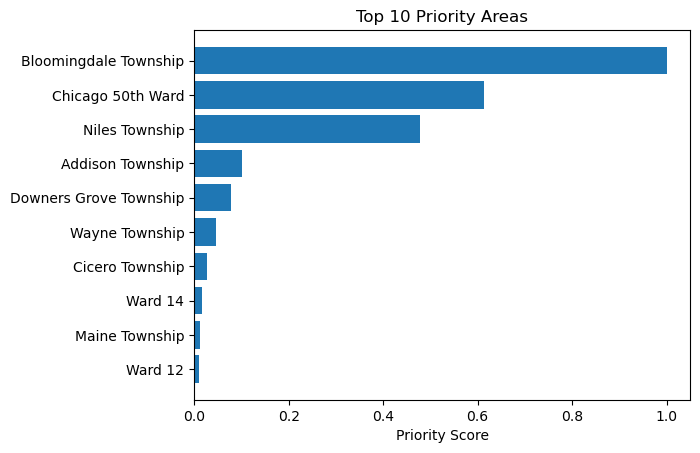

In [16]:
import matplotlib.pyplot as plt

plt.barh(top10['area'], top10['gap_score'])
plt.xlabel('Priority Score')
plt.title('Top 10 Priority Areas')
plt.gca().invert_yaxis()
plt.savefig('top10_gap_scores.png')
plt.show()